# EEG Step 3A — Distribution & Extreme-Value Audit

**Purpose:** inspect the ROI-level EEG power distributions, summarize skew/spread, and flag potentially extreme observations without deleting or transforming data.

**Scope:** Math and Reading; Control and Experiment; PRE and POST; conditions; 5 frequency bands; 5 ROIs; absolute and relative power.

> This notebook is exploratory QC only. Outlier flags are not exclusion decisions, no inferential tests are performed, and original values are preserved.

## 0. Setup and file discovery
Run this notebook from the project `analysis` directory when possible. It will also search common project/output locations for the ROI long CSV.

In [28]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



# Prefer project-relative paths, then common locations.
CANDIDATE_DIRS = [Path.cwd(), Path.cwd() / 'eeg_roi_step2_outputs', Path.cwd() / 'Results',
                   Path.cwd().parent, Path.cwd().parent / 'Results', Path('/mnt/data')]
INPUT_NAME = 'eeg_roi_power_long.csv'
input_path = next((d / INPUT_NAME for d in CANDIDATE_DIRS if (d / INPUT_NAME).exists()), None)
if input_path is None:
    raise FileNotFoundError(f"Could not locate {INPUT_NAME}. Place it in the analysis folder or a recognized output folder.")
print('Input file:', input_path)
# Outputs are written alongside this notebook, in a dedicated directory.
OUT_DIR = Path.cwd() / 'eeg_step3A_distribution_audit_outputs'
PLOT_DIR = OUT_DIR / 'plots'
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)


Input file: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/eeg_roi_power_long.csv


## 1. Load data and validate expected fields

In [29]:
df = pd.read_csv(input_path)
required = {'subject_id','session','run','condition','band','roi','absolute_power_roi','relative_power_roi','task','group'}
missing_cols = required - set(df.columns)
if missing_cols:
    raise ValueError(f'Missing required columns: {sorted(missing_cols)}')

for col in ['absolute_power_roi','relative_power_roi']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Rows:', len(df))
print('Unique participants:', df['subject_id'].nunique())
print('Tasks:', sorted(df['task'].dropna().unique()))
print('Groups:', sorted(df['group'].dropna().unique()))
print('Sessions:', sorted(df['session'].dropna().unique()))
print('Conditions:', sorted(df['condition'].dropna().unique()))
print('Bands:', sorted(df['band'].dropna().unique()))
print('ROIs:', sorted(df['roi'].dropna().unique()))
df.head()


Rows: 8000
Unique participants: 63
Tasks: ['Math', 'Reading']
Groups: ['Control', 'Experiment']
Sessions: ['POST', 'PRE']
Conditions: ['Activity', 'Activity1', 'Activity2', 'Baseline']
Bands: ['alpha', 'beta', 'delta', 'gamma', 'theta']
ROIs: ['Central', 'Frontal', 'Occipital', 'Parietal', 'Temporal']


,subject_id,session,run,condition,band,roi,absolute_power_roi,relative_power_roi,channels_in_roi,channel_rows_in_roi,task,group
0,Mc02,POST,1,Baseline,alpha,Central,1.949249e+05,2.974069,7,7,Math,Control
1,Mc02,POST,1,Baseline,alpha,Frontal,2.059453e+05,2.826049,7,7,Math,Control
2,Mc02,POST,1,Baseline,alpha,Occipital,2.646393e+06,2.780578,3,3,Math,Control
3,Mc02,POST,1,Baseline,alpha,Parietal,1.215410e+06,2.811652,9,9,Math,Control
4,Mc02,POST,1,Baseline,alpha,Temporal,8.045918e+05,2.551062,6,6,Math,Control


## 2. Basic integrity checks

In [30]:
integrity = pd.DataFrame({
    'check':['Rows','Duplicate participant-session-run-condition-band-ROI keys',
             'Missing absolute power','Missing relative power',
             'Non-positive absolute power','Negative relative power'],
    'value':[len(df),
             df.duplicated(['subject_id','session','run','condition','band','roi']).sum(),
             df['absolute_power_roi'].isna().sum(),
             df['relative_power_roi'].isna().sum(),
             (df['absolute_power_roi'] <= 0).sum(),
             (df['relative_power_roi'] < 0).sum()]
})
integrity


,check,value
0,Rows,8000
1,Duplicate participant-session-run-condition-ba...,0
2,Missing absolute power,0
3,Missing relative power,0
4,Non-positive absolute power,0
5,Negative relative power,0


## 3. Descriptive statistics
Summaries are stratified by task, group, session, condition, band, ROI, and power metric. Mean and SD are included alongside median and quartiles because EEG power distributions can be skewed.

In [31]:
long_metrics = df.melt(
    id_vars=['subject_id','task','group','session','run','condition','band','roi'],
    value_vars=['absolute_power_roi','relative_power_roi'],
    var_name='metric', value_name='value')
summary = long_metrics.groupby(['task','group','session','condition','band','roi','metric'], dropna=False)['value'].agg(
    n='count', mean='mean', sd='std', median='median', q1=lambda x:x.quantile(.25),
    q3=lambda x:x.quantile(.75), minimum='min', maximum='max').reset_index()
summary.to_csv(OUT_DIR / 'eeg_power_distribution_summary.csv', index=False)
summary.head()


,task,group,session,condition,band,roi,metric,n,mean,sd,median,q1,q3,minimum,maximum
0,Math,Control,POST,Activity1,alpha,Central,absolute_power_roi,15,1.121400e+05,3.091869e+05,2.165009e+03,84.185029,6.543590e+04,0.888171,1.208550e+06
1,Math,Control,POST,Activity1,alpha,Central,relative_power_roi,15,4.343004e+00,2.486900e+00,3.719769e+00,2.716797,4.160151e+00,2.218530,1.161004e+01
2,Math,Control,POST,Activity1,alpha,Frontal,absolute_power_roi,15,1.189679e+05,3.318628e+05,2.469283e+03,86.749308,7.081133e+04,0.919974,1.298327e+06
3,Math,Control,POST,Activity1,alpha,Frontal,relative_power_roi,15,3.706420e+00,2.344001e+00,3.282975e+00,2.353402,3.680862e+00,1.622321,1.122092e+01
4,Math,Control,POST,Activity1,alpha,Occipital,absolute_power_roi,15,1.144344e+07,2.535150e+07,1.296356e+06,108892.390199,9.301415e+06,0.955529,9.944485e+07


## 4. Robust extreme-value flags (IQR and MAD)
Flags are calculated within task × group × session × condition × band × ROI × metric cells. IQR and MAD flags are only generated for cells with at least 5 observations. They identify candidates for inspection, **not automatic exclusions**.

In [32]:
def flag_cell(s):
    x = s.astype(float)
    out = pd.DataFrame(index=s.index, data={'iqr_flag':False,'mad_flag':False})
    if x.notna().sum() < 5:
        return out
    q1, q3 = x.quantile(.25), x.quantile(.75)
    iqr = q3-q1
    if iqr > 0:
        out['iqr_flag'] = (x < q1-1.5*iqr) | (x > q3+1.5*iqr)
    med = x.median()
    mad = (x-med).abs().median()
    if mad > 0:
        robust_z = 0.6745*(x-med)/mad
        out['mad_flag'] = robust_z.abs() > 3.5
    return out

flag_group_cols = ['task','group','session','condition','band','roi','metric']
flag_parts = []
for keys, part in long_metrics.groupby(flag_group_cols, dropna=False):
    flags = flag_cell(part['value'])
    flagged_part = part.join(flags)
    for col, val in zip(flag_group_cols, keys):
        flagged_part[col] = val
    flag_parts.append(flagged_part)
flagged = pd.concat(flag_parts, ignore_index=True) if flag_parts else long_metrics.copy()
flagged['any_flag'] = flagged.get('iqr_flag',False) | flagged.get('mad_flag',False)
flagged.to_csv(OUT_DIR / 'eeg_power_extreme_flags.csv', index=False)
flag_summary = flagged.groupby(flag_group_cols, dropna=False).agg(
    n=('value','count'), iqr_flag_count=('iqr_flag','sum'), mad_flag_count=('mad_flag','sum'),
    any_flag_count=('any_flag','sum')).reset_index()
flag_summary.to_csv(OUT_DIR / 'eeg_power_extreme_flag_summary.csv', index=False)
print('Flagged observations (IQR):', int(flagged['iqr_flag'].sum()))
print('Flagged observations (MAD):', int(flagged['mad_flag'].sum()))
print('Flagged observations by either method:', int(flagged['any_flag'].sum()))


Flagged observations (IQR): 1715
Flagged observations (MAD): 3142
Flagged observations by either method: 3298


## 5. Plot 1 — Absolute power distributions (log10 scale)
Only positive absolute-power values are plotted on a logarithmic scale. The original data are not changed.

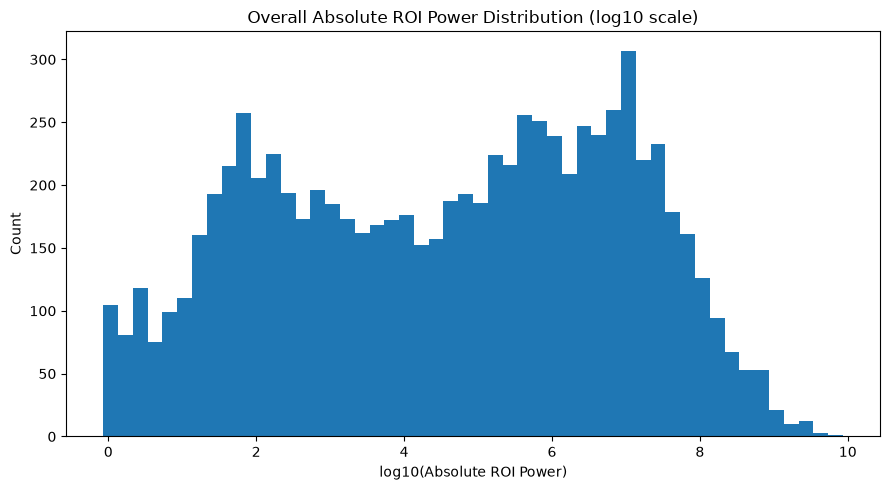

In [33]:
positive_abs = df.loc[df['absolute_power_roi'] > 0, 'absolute_power_roi'].dropna()
plt.figure(figsize=(9,5))
plt.hist(np.log10(positive_abs), bins=50)
plt.xlabel('log10(Absolute ROI Power)')
plt.ylabel('Count')
plt.title('Overall Absolute ROI Power Distribution (log10 scale)')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'absolute_power_overall_log10_histogram.png', dpi=200)
plt.show()


## 6. Plot 2 — Relative power distribution
Relative band power should be interpretable in percentage-like units as generated by Step 2; this plot checks the distribution and range.

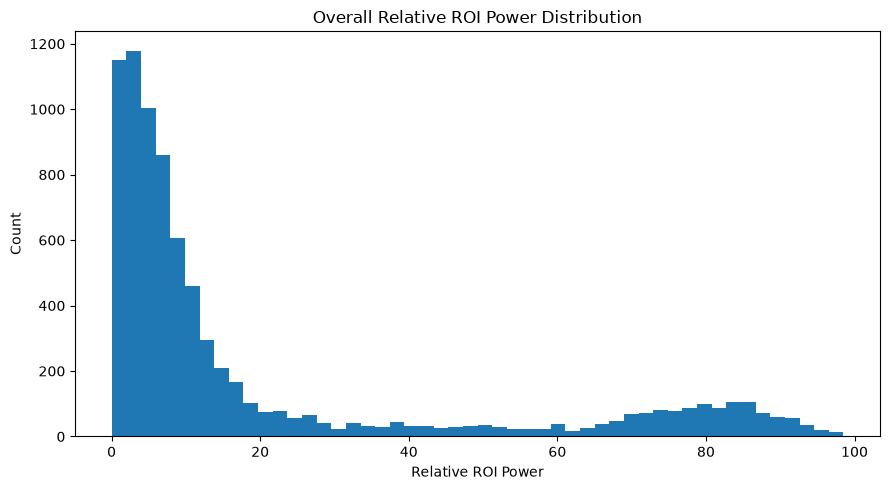

In [34]:
rel = df['relative_power_roi'].dropna()
plt.figure(figsize=(9,5))
plt.hist(rel, bins=50)
plt.xlabel('Relative ROI Power')
plt.ylabel('Count')
plt.title('Overall Relative ROI Power Distribution')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'relative_power_overall_histogram.png', dpi=200)
plt.show()


## 7. Plot 3 — Absolute power by band (log scale)
The boxplot is for visualization only. Outliers are displayed rather than hidden.

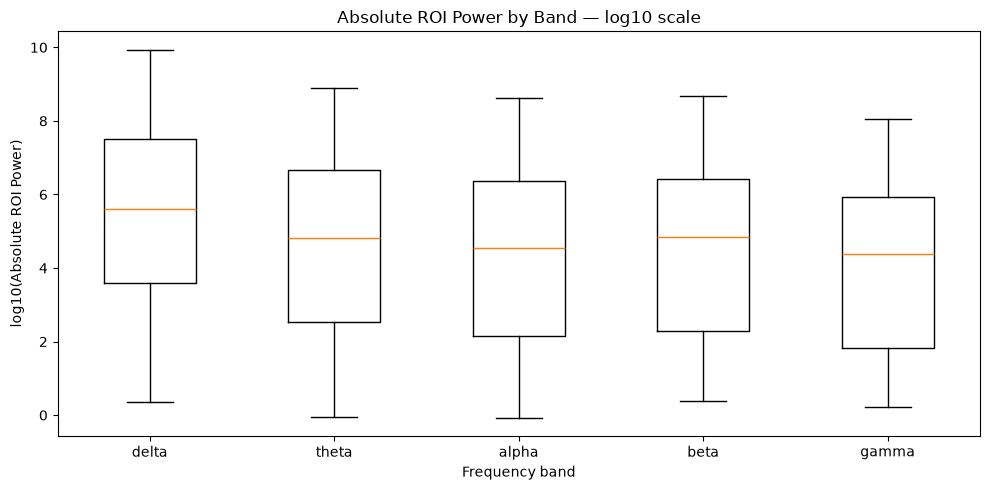

In [35]:
bands_order = [b for b in ['delta','theta','alpha','beta','gamma'] if b in df['band'].astype(str).str.lower().unique()]
abs_by_band = [np.log10(df.loc[(df['band'].astype(str).str.lower()==b) & (df['absolute_power_roi']>0), 'absolute_power_roi'].dropna()) for b in bands_order]
plt.figure(figsize=(10,5))
plt.boxplot(abs_by_band, tick_labels=bands_order, showfliers=True)
plt.xlabel('Frequency band')
plt.ylabel('log10(Absolute ROI Power)')
plt.title('Absolute ROI Power by Band — log10 scale')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'absolute_power_by_band_log10_boxplot.png', dpi=200)
plt.show()


## 8. Plot 4 — Relative power by band


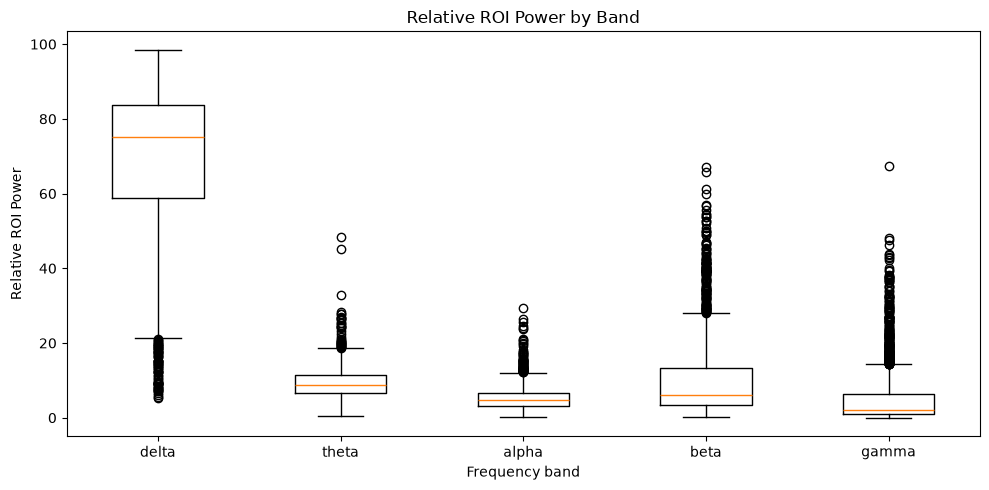

In [36]:
rel_by_band = [df.loc[df['band'].astype(str).str.lower()==b, 'relative_power_roi'].dropna() for b in bands_order]
plt.figure(figsize=(10,5))
plt.boxplot(rel_by_band, tick_labels=bands_order, showfliers=True)
plt.xlabel('Frequency band')
plt.ylabel('Relative ROI Power')
plt.title('Relative ROI Power by Band')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'relative_power_by_band_boxplot.png', dpi=200)
plt.show()


## 9. Plot 5 — ROI-wise absolute power distributions
Each ROI is shown separately to avoid mixing regional distributions. Values are plotted as log10 absolute power.

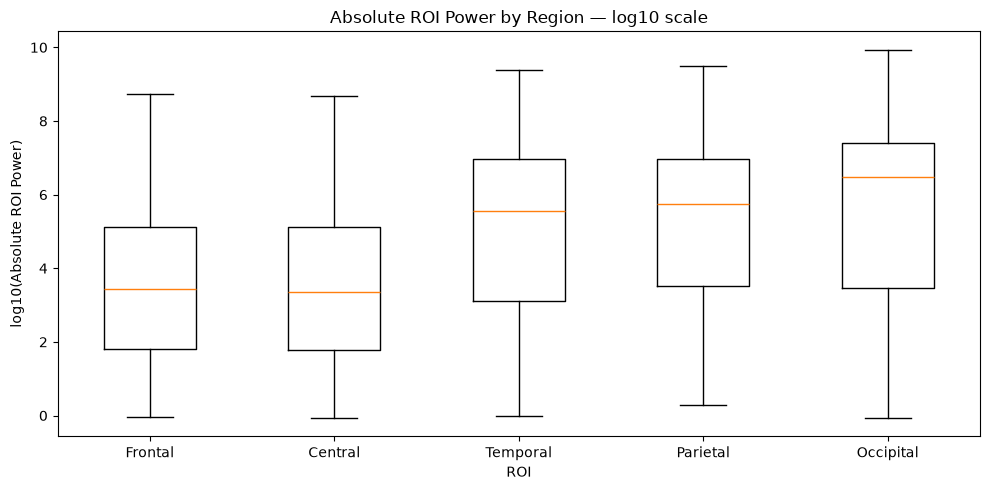

In [37]:
roi_order = [r for r in ['Frontal','Central','Temporal','Parietal','Occipital'] if r in df['roi'].unique()]
abs_by_roi = [np.log10(df.loc[(df['roi']==r) & (df['absolute_power_roi']>0), 'absolute_power_roi'].dropna()) for r in roi_order]
plt.figure(figsize=(10,5))
plt.boxplot(abs_by_roi, tick_labels=roi_order, showfliers=True)
plt.xlabel('ROI')
plt.ylabel('log10(Absolute ROI Power)')
plt.title('Absolute ROI Power by Region — log10 scale')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'absolute_power_by_roi_log10_boxplot.png', dpi=200)
plt.show()


## 10. Plot 6 — ROI-wise relative power distributions


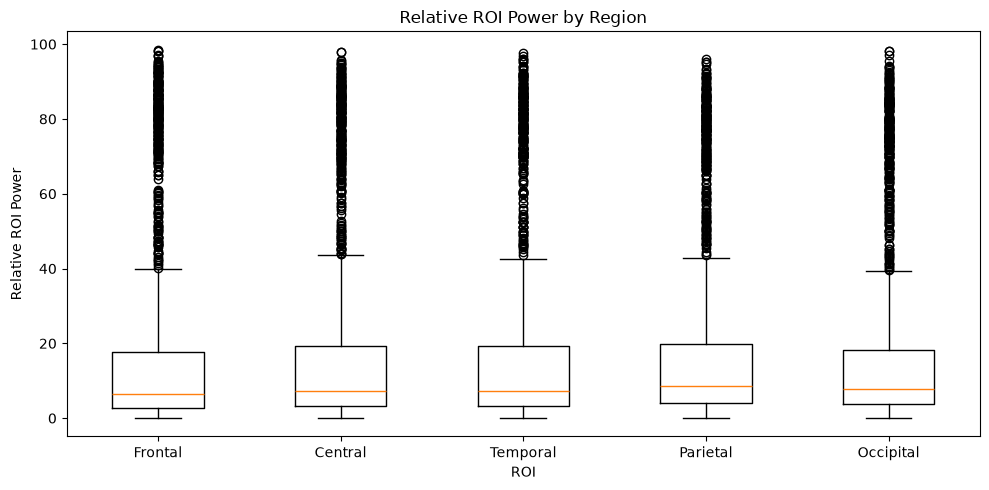

In [38]:
rel_by_roi = [df.loc[df['roi']==r, 'relative_power_roi'].dropna() for r in roi_order]
plt.figure(figsize=(10,5))
plt.boxplot(rel_by_roi, tick_labels=roi_order, showfliers=True)
plt.xlabel('ROI')
plt.ylabel('Relative ROI Power')
plt.title('Relative ROI Power by Region')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'relative_power_by_roi_boxplot.png', dpi=200)
plt.show()


## 11. Review the flagged extreme observations
The table below is sorted by absolute value descending. Review participant, task, group, session, condition, band, ROI, and metric context before deciding whether any observation is an artifact or valid variability.

In [39]:
flagged_review = flagged.loc[flagged['any_flag']].copy()
flagged_review['absolute_value'] = flagged_review['value'].abs()
flagged_review = flagged_review.sort_values('absolute_value', ascending=False)
flagged_review.head(100)


,subject_id,task,group,session,run,condition,band,roi,metric,value,iqr_flag,mad_flag,any_flag,absolute_value
4116,Mc09,Math,Control,PRE,1,Baseline,delta,Occipital,absolute_power_roi,8.617234e+09,True,True,True,8.617234e+09
13014,Re09,Reading,Experiment,POST,2,Activity,delta,Occipital,absolute_power_roi,5.424984e+09,True,True,True,5.424984e+09
8765,Me10,Math,Experiment,PRE,3,Activity2,delta,Occipital,absolute_power_roi,4.729225e+09,True,True,True,4.729225e+09
1119,Mc12,Math,Control,POST,3,Activity2,delta,Occipital,absolute_power_roi,4.421564e+09,True,True,True,4.421564e+09
4959,Me04,Math,Experiment,POST,2,Activity1,delta,Occipital,absolute_power_roi,3.308835e+09,True,True,True,3.308835e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
433,Mc19,Math,Control,POST,2,Activity1,delta,Temporal,absolute_power_roi,5.408442e+08,True,True,True,5.408442e+08
3367,Mc10,Math,Control,PRE,3,Activity2,delta,Occipital,absolute_power_roi,5.400409e+08,False,True,True,5.400409e+08
365,Mc07,Math,Control,POST,2,Activity1,delta,Occipital,absolute_power_roi,5.346726e+08,True,True,True,5.346726e+08
4123,Mc19,Math,Control,PRE,1,Baseline,delta,Occipital,absolute_power_roi,5.322082e+08,True,True,True,5.322082e+08


## 12. Export an audit manifest


In [40]:
manifest = pd.DataFrame([
    {'file':'eeg_power_distribution_summary.csv','description':'Stratified descriptive statistics'},
    {'file':'eeg_power_extreme_flags.csv','description':'Observation-level IQR/MAD flags; no data removed'},
    {'file':'eeg_power_extreme_flag_summary.csv','description':'Flag counts per analysis cell'},
    {'file':'plots/','description':'Exploratory distribution plots'}
])
manifest.to_csv(OUT_DIR / 'step3A_output_manifest.csv', index=False)
print('Audit outputs saved to:', OUT_DIR.resolve())
print('Plots saved to:', PLOT_DIR.resolve())
print('Files:', sorted(p.name for p in OUT_DIR.iterdir()))


Audit outputs saved to: /Users/ananyosen/Documents/Term Project/analysis/eeg_step3A_distribution_audit_outputs
Plots saved to: /Users/ananyosen/Documents/Term Project/analysis/eeg_step3A_distribution_audit_outputs/plots
Files: ['eeg_power_distribution_summary.csv', 'eeg_power_extreme_flag_summary.csv', 'eeg_power_extreme_flags.csv', 'plots', 'step3A_output_manifest.csv']


## Step 3A completion checklist

After the notebook runs, inspect the integrity table, flag counts, plots, and the flagged-observation table. Do not delete any values based only on these flags. Upload the CSV outputs and, if possible, the plots for review before proceeding to the next analysis step.